# 04. Categorical variables, Weight of Evidence and Information Value

**The question this notebook answers:** how do we turn text categories (job title, purpose, state) and numeric ranges into stable, explainable numbers, and which fields actually separate defaulters from repaid loans?

**What the brief asks:**
- Clean and group the categorical fields: normalise `emp_title` into a small set of **job groups**, **order `emp_length`**, and **merge rare levels** of `purpose`, `home_ownership` and `addr_state` with a stated minimum group size.
- Compute **Weight of Evidence (WoE)** and **Information Value (IV)** for the main categorical and binned numeric fields, **rank them by IV**, and **comment on any IV that looks too good to be true**.
- Fit the groups and bins on loans up to the fit cutoff and **store them in `data_spec.json`**.

**Terms used in this notebook**
- **Group / bin:** one category of a field (a job group, a state, a FICO range).
- **WoE of a group:** `ln(share of all repaid loans in the group / share of all defaulted loans in the group)`. Positive means the group is safer than average, negative means riskier, zero means average. Taking the logarithm puts it on the same scale as the log-odds a logistic regression uses, so it can feed a scorecard directly.
- **IV of a field:** sum over groups of `(share repaid - share defaulted) x WoE`. It measures how well one field separates the two outcomes.
- **Reading IV:** under 0.02 useless, 0.02 to 0.1 weak, 0.1 to 0.3 medium, 0.3 to 0.5 strong, above 0.5 suspiciously strong.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from statsmodels.stats.proportion import proportion_confint

from credit_risk.binning import assign_bins, fit_edges
from credit_risk.categorical import JOB_RULES, CategoryGrouper, group_job_titles
from credit_risk.cleaning import Cleaner
from credit_risk.io import FIT_CUTOFF, load_applications
from credit_risk.woe import information_value, strength, woe_table

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

joined = load_applications()
clean = Cleaner().fit(joined).transform(joined)
grouped = CategoryGrouper().fit(clean).transform(clean)      # groups are learned on the fit window only
fit = grouped[grouped.issue_d <= FIT_CUTOFF]
spec = json.load(open("contract/data_spec.json"))
print(f"{len(fit):,} loans in the fit window (to {FIT_CUTOFF.date()}); all tables below use these loans only")

14,373 loans in the fit window (to 2014-12-31); all tables below use these loans only


## 1. WoE and IV on one small field

`home_ownership` has three levels, which is small enough to follow every number.

In [2]:
t = woe_table(fit.home_ownership_group, fit.defaulted)
print(t.round(4).to_string(index=False))
print(f"\nIV of home_ownership = {information_value(t):.4f}  ({strength(information_value(t))})")

# the same WoE for the first group, by hand
g = t.iloc[0]
n_rep, n_def = t.repaid.sum(), t.defaults.sum()
share_rep = (g.repaid + 0.5) / (n_rep + 0.5 * len(t))
share_def = (g.defaults + 0.5) / (n_def + 0.5 * len(t))
print(f"\nby hand for {g.group}: ln({share_rep:.4f} / {share_def:.4f}) = {np.log(share_rep / share_def):.4f}   (table: {g.woe:.4f})")

   group  loans  defaults  repaid  default_rate     woe  iv_part
MORTGAGE   7407      1137    6270        0.1535  0.1388   0.0095
     OWN   1406       240    1166        0.1707  0.0109   0.0000
    RENT   5560      1101    4459        0.1980 -0.1698   0.0118

IV of home_ownership = 0.0213  (weak)

by hand for MORTGAGE: ln(0.5271 / 0.4588) = 0.1388   (table: 0.1388)


**Reading it.** Renters (RENT) default more than the average (WoE negative), people with a mortgage default less (WoE positive). The IV of 0.021 is just above the 0.02 line: home ownership separates the outcomes, but only weakly. A small constant (0.5) is added to each count so that a group with no defaults, or no repayments, still gets a finite WoE instead of infinity.

## 2. Job titles (`emp_title`)

Free text is unusable as it stands: thousands of different strings, typed in different cases and styles. The task is to collapse it into a **small number of meaningful groups**.

### 2a. A change in what the field contains
Before grouping, the stability check in notebook 06 showed that this field changes meaning around October 2013. Looking at the titles themselves explains it.

In [3]:
raw_group = group_job_titles(clean.emp_title)                 # keyword rules, ignoring the date
has_title = clean.emp_title.notna()
by_month = (raw_group[has_title].eq("other_job").groupby(clean.issue_d[has_title].dt.to_period("M")).mean() * 100).round(1)
print("share of titles that no keyword rule can place (%), by issue month:")
print(by_month.loc["2013-05":"2013-12"].to_string())
print("\nexamples before October 2013 :", clean.emp_title[has_title & (clean.issue_d < "2013-10-01")].dropna().sample(5, random_state=1).tolist())
print("examples from October 2013     :", clean.emp_title[has_title & (clean.issue_d >= "2013-10-01")].dropna().sample(5, random_state=1).tolist())

share of titles that no keyword rule can place (%), by issue month:
issue_d
2013-05    63.9
2013-06    67.3
2013-07    65.8
2013-08    65.6
2013-09    68.9
2013-10    17.8
2013-11    13.6
2013-12    13.7
Freq: M

examples before October 2013 : ['theranos inc', 'promedica health systems', 'the law offices of michael b. brehne', 'garda', 'trillium computer and engineering servic']
examples from October 2013     : ['quality control', 'buyer', 'finance manager', 'drilling fluids engineer', 'lrv mechanic']


**Reading it.** Up to September 2013 the field mostly holds *employer names* ("state farm insurance", "at&t"); from October 2013 it holds *job titles* ("teacher", "registered nurse"). The share of titles no keyword rule can place falls from roughly 64% to 69% (May to September) to 14% to 18% (October to December), within a single month. Mixing the two eras would blend two different variables, so **loans before October 2013 get their own group (`employer_name_era`)** and the grouping is judged on loans from October 2013.

### 2b. Why not one code per title?

In [4]:
later = fit[(fit.issue_d >= "2013-10-01") & fit.emp_title.notna()]
counts = later.emp_title.value_counts()
for n in (20, 50, 200):
    print(f"the {n:>3} most common titles leave {100 * (1 - counts.iloc[:n].sum() / len(later)):.0f}% of loans in an 'other' level")
print(f"\n{counts.size:,} distinct titles for {len(later):,} loans; {int((counts == 1).sum()):,} titles appear exactly once")

the  20 most common titles leave 83% of loans in an 'other' level
the  50 most common titles leave 75% of loans in an 'other' level
the 200 most common titles leave 60% of loans in an 'other' level

5,058 distinct titles for 10,151 loans; 4,146 titles appear exactly once


**Reading it.** Titles are extremely scattered: even the 200 most common leave over half of loans uncovered, and most titles appear once. A WoE value for a title seen once is noise. So we compare ways of grouping.

### 2c. Comparing the options
IV is shown twice: on the loans the groups were learned from, and on later loans using the WoE learned earlier. More groups always look better on the loans they were learned from, so the **later-loans column is the honest one**.

In [5]:
print(pd.read_csv("reports/a4_emp_title_grouping/tables/grouping_options.csv").round(4).to_string(index=False))

           option  groups  smallest_group_loans  share_in_other_pct  iv_on_training_loans  iv_on_later_loans
   keyword_groups      10                   200             13.2391                0.0296             0.0130
    top_20_titles      22                    23             77.8127                0.0306             0.0211
    top_50_titles      52                    10             69.9285                0.0695             0.0252
   top_200_titles     202                     3             55.5032                0.1884             0.0385
missing_flag_only       2                   360              0.0000                0.0023             0.0009


**Reading it.** The top 200 titles reach the highest IV on later loans (0.039), but with 202 groups, some containing 3 loans, whose WoE is mostly noise (their IV on the learning loans, 0.19, is five times higher than out of time). **Keyword groups** give up a little signal (0.013) for stability, size (every group has at least 200 loans) and the ability to explain each group to a credit officer. That is the choice.

### 2d. The keyword rules
A title gets the **first** group whose keywords it contains, so the order matters: "sales manager" is a manager, "medical assistant" is healthcare, "security officer" is public safety.

In [6]:
print("group order:", [name for name, _ in JOB_RULES] + ["other_job", "missing", "employer_name_era"])
examples = ["registered nurse", "sales manager", "medical assistant", "security officer", "truck driver", "software engineer", "teacher", "owner", "zzz"]
print(pd.Series(group_job_titles(examples).values, index=examples).to_string())

group order: ['executive_owner', 'healthcare', 'education', 'public_safety_government', 'professional_technical', 'trades_transport_labor', 'manager_supervisor', 'sales_service_office', 'other_job', 'missing', 'employer_name_era']
registered nurse                   healthcare
sales manager              manager_supervisor
medical assistant                  healthcare
security officer     public_safety_government
truck driver           trades_transport_labor
software engineer      professional_technical
teacher                             education
owner                         executive_owner
zzz                                 other_job


                   group  loans  defaults  repaid  default_rate    woe  iv_part  ci_low  ci_high
  trades_transport_labor   1181       237     944         0.201 -0.170    0.003   0.179    0.224
               other_job   1389       272    1117         0.196 -0.139    0.003   0.176    0.218
    sales_service_office   1394       265    1129         0.190 -0.102    0.001   0.170    0.212
                 missing    824       155     669         0.188 -0.090    0.001   0.163    0.216
              healthcare    780       136     644         0.174  0.002    0.000   0.149    0.203
      manager_supervisor   2055       355    1700         0.173  0.015    0.000   0.157    0.190
public_safety_government    356        58     298         0.163  0.080    0.000   0.128    0.205
         executive_owner   1131       173     958         0.153  0.159    0.002   0.133    0.175
               education    457        69     388         0.151  0.171    0.001   0.121    0.187
  professional_technical   140

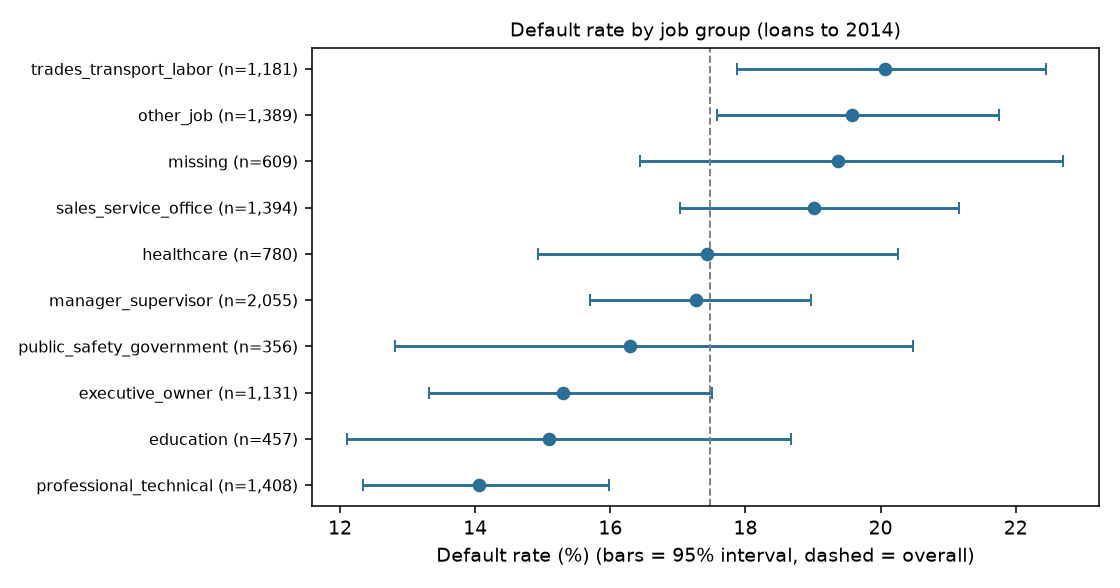

In [7]:
era = fit[fit.job_group != "employer_name_era"]
jt = woe_table(era.job_group, era.defaulted)
ci = [proportion_confint(r.defaults, r.loans, method="wilson") for r in jt.itertuples()]
jt["ci_low"], jt["ci_high"] = [c[0] for c in ci], [c[1] for c in ci]
print(jt.sort_values("default_rate", ascending=False).round(3).to_string(index=False))
print(f"\nIV of job_group on these loans = {information_value(jt):.4f}  ({strength(information_value(jt))})")
display(Image("reports/a4_emp_title_grouping/figures/default_rate_by_job_group.png", width=800))

**Reading it.** Default rates run from 14.1% (professional and technical) to 20.1% (trades, transport and labour), and several groups' intervals overlap, so the differences are modest. The IV is 0.0195 on these loans (right at the 0.02 line, formally "useless") and 0.013 on later loans: **a very weak field**.

**Decision: job group stays in the contract, but is restricted and not a default model input.** Occupation can stand in for characteristics the data does not contain (sex, age, ethnicity), which would be indirect discrimination that we cannot test for because those fields are absent. Its predictive value is small, so leaving it out costs almost nothing. The fairness discussion (notebook 06) treats it together with `zip_code` and `addr_state`.

## 3. Employment length: an ordered field
`emp_length` arrives as text ("< 1 year", "10+ years"). It has a natural order, so it becomes a number from 0 to 10, with missing kept as its own level (notebook 03 showed blanks follow the verification process, not risk).

  years  loans  default rate  ci low  ci high
missing    686         0.195   0.167    0.227
      0   1050         0.197   0.174    0.222
      1    874         0.183   0.159    0.210
      2   1208         0.184   0.163    0.207
      3   1107         0.173   0.152    0.197
      4    801         0.152   0.129    0.179
      5    889         0.183   0.159    0.210
      6    775         0.190   0.164    0.219
      7    823         0.181   0.156    0.209
      8    718         0.180   0.153    0.209
      9    562         0.174   0.145    0.208
     10   4880         0.155   0.145    0.165


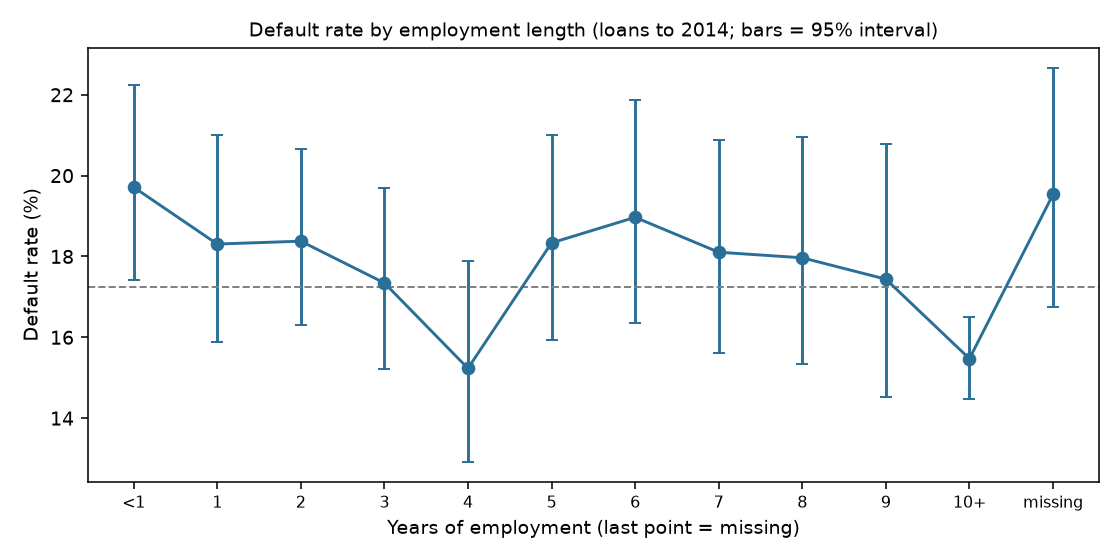

In [8]:
rows = []
for level, d in fit.groupby(fit.emp_length_years.fillna(-1)):
    lo, hi = proportion_confint(int(d.defaulted.sum()), len(d), method="wilson")
    rows.append({"years": "missing" if level == -1 else int(level), "loans": len(d), "default rate": d.defaulted.mean(), "ci low": lo, "ci high": hi})
print(pd.DataFrame(rows).round(3).to_string(index=False))
display(Image("reports/a4_rare_level_merging/figures/default_rate_by_emp_length.png", width=700))

**Reading it.** The default rate is about 15% to 19% for 1 to 9 years (the dip at 4 years is 15.2%), lower for 10+ years (15.5%), and higher for under one year (19.7%) and missing (19.5%). It is **not a clean staircase**, which is why a monotone binning (section 5) merges it into a few steadier groups, and why its IV is only about 0.01. Length of employment also tends to rise with age, so it is flagged in the fairness review.

## 4. Rare levels: a stated minimum group size
A level with a handful of loans gets a WoE that is mostly noise. The rule: **levels with fewer than 1% of the fit-window loans (about 144 of 14,373) merge into one `other_<field>` level**; a level never seen when fitting (a new state, say) maps there too.

In [9]:
spec_groups = CategoryGrouper().fit(clean).spec_entries()
rows = []
for f, e in spec_groups.items():
    before = fit[f].nunique()
    after = fit[f"{f}_group"].nunique()
    share_other = 100 * (fit[f"{f}_group"] == e["other_label"]).mean()
    rows.append({"field": f, "levels before": before, "groups after": after, "levels merged": len(e["merged_levels"]),
                 "loans in other (%)": round(share_other, 1), "smallest group (loans)": int(fit[f"{f}_group"].value_counts().min())})
print(pd.DataFrame(rows).to_string(index=False))
print("\npurpose levels merged into other_purpose:", spec_groups["purpose"]["merged_levels"])
print("states merged:", len(spec_groups["addr_state"]["merged_levels"]), "of", fit.addr_state.nunique(), "-> e.g.", spec_groups["addr_state"]["merged_levels"][:8])

           field  levels before  groups after  levels merged  loans in other (%)  smallest group (loans)
         purpose             13             6              8                 4.4                     223
  home_ownership              3             3              0                 0.0                    1406
      addr_state             47            32             16                 5.9                     147
application_type              1             1              0                 0.0                   14373

purpose levels merged into other_purpose: ['car', 'house', 'medical', 'moving', 'renewable_energy', 'small_business', 'vacation', 'wedding']
states merged: 16 of 47 -> e.g. ['AK', 'AR', 'DC', 'DE', 'HI', 'MS', 'MT', 'NE']


In [10]:
cmp = pd.read_csv("reports/a4_rare_level_merging/tables/threshold_comparison.csv")
print(cmp[cmp.field.isin(["purpose", "addr_state"])].round(4).to_string(index=False))

     field  min_share_pct  min_loans_in_training  levels_before  groups_after  levels_merged  loans_in_other_pct  smallest_group_loans  iv_on_training_loans  iv_on_later_loans
   purpose           0.00                      0             13            13              0              0.0000                     5                0.0275             0.0138
   purpose           0.25                     24             13            12              2              0.2675                    25                0.0277             0.0141
   purpose           0.50                     47             13            10              4              1.1342                    53                0.0259             0.0140
   purpose           1.00                     94             13             7              7              3.3597                    96                0.0253             0.0152
   purpose           2.00                    187             13             5              9              5.8635        

**Reading it.** Why 1%: at about 100 loans a group's default rate carries an uncertainty of roughly 4 percentage points, and below that the WoE wobbles. A 2% threshold pushes about a quarter of state loans into "other" and lowers the later-loan IV of `purpose` (0.0102); 0.5% leaves groups as small as 50 loans. For `purpose`, 1% gives the best later-loan IV of the thresholds tried (0.0152). The comparison table was run on loans to mid-2014 (so 1% was 94 loans); the contract applies the same 1% rule to the whole fit window (144 loans), which merges slightly more (`purpose` ends with 6 groups instead of 7).

**State is mostly noise.** Its IV looks like 0.03 on the loans it was learned from, but falls to about 0.003 to 0.01 on later loans at every threshold. It also carries the location-proxy risk, so it stays restricted. The merging is applied because the brief asks for it and the data contract needs it.

## 5. Binning numeric fields
WoE needs groups, so a numeric field is cut into **bins**. The method (**monotone merge**): start with 20 equal-sized bins, then merge neighbours until (a) every bin holds at least 5% of the loans and (b) the default rate moves in one direction across bins. This gives a pattern a credit officer can read ("higher FICO, lower risk"), at the cost of ignoring real but wobbly patterns in a few weak fields. Missing values get their own bin. We compared three methods on 30 fields, with the bins learned on loans to mid-2014 and judged on later loans:

In [11]:
print(pd.read_csv("reports/a4_binning_comparison/tables/method_summary.csv").round(3).to_string(index=False))

         method  avg_bins  avg_iv_training  avg_iv_later  pct_fields_one_directional_on_later  smallest_bin_pct  iv_kept_pct
monotonic_merge     5.500            0.047         0.050                               40.000             2.782      107.533
    quantile_10     8.733            0.047         0.049                               20.000             3.863      104.859
         tree_6     5.533            0.053         0.049                               33.333             2.761       92.782


The three methods tie on later-loan IV (about 0.05). Monotone merge needs the fewest bins and loses no IV out of time (107% of the learning-sample IV is kept), so it is chosen for the contract. Applied to FICO:

In [12]:
ds = pd.read_parquet("contract/analytical_dataset.parquet")
ds = ds[pd.to_datetime(ds.issue_d) <= FIT_CUTOFF]
x, y = ds.fico_mid_treated, ds.defaulted
edges = fit_edges(x, y, "monotonic")
tab = woe_table(assign_bins(x, edges), y)
bounds = [f"below {edges[0]:.0f}"] + [f"{lo:.0f} to under {hi:.0f}" for lo, hi in zip(edges[:-1], edges[1:])] + [f"{edges[-1]:.0f} and above"]
tab.insert(1, "FICO range", bounds)
print(tab[["FICO range", "loans", "default_rate", "woe", "iv_part"]].round(4).to_string(index=False))
print(f"\nIV of FICO = {information_value(tab):.4f}  ({strength(information_value(tab))})")
print("same edges as stored in the contract:", [float(e) for e in edges] == spec["woe"]["fico_mid_treated"]["edges"])

      FICO range  loans  default_rate     woe  iv_part
       below 667   1281        0.2326 -0.3747   0.0141
667 to under 677   2679        0.2176 -0.2881   0.0169
677 to under 687   2307        0.1938 -0.1421   0.0034
687 to under 692   1040        0.1913 -0.1277   0.0012
692 to under 697   1052        0.1673  0.0355   0.0001
697 to under 707   1690        0.1521  0.1498   0.0025
707 to under 722   1874        0.1505  0.1623   0.0033
722 to under 732    803        0.1233  0.3903   0.0075
732 to under 752    798        0.0890  0.7528   0.0243
   752 and above    849        0.0777  0.8995   0.0351

IV of FICO = 0.1084  (medium)
same edges as stored in the contract: True


**Reading it.** The default rate falls steadily from 23% (lowest FICO) to under 8% (highest), and WoE rises from negative to positive in the same order, with each bin holding a sensible share of loans. The stored bins in `data_spec.json` are exactly these edges.

## 6. Ranking by IV, and the "too good to be true" check

                        field        kind  bins_or_groups     iv   strength           role
                    sub_grade categorical              35 0.5035 suspicious platform score
                     int_rate     numeric              11 0.4639     strong platform score
                        grade categorical               7 0.4544     strong platform score
                         term categorical               2 0.1952     medium          input
             fico_mid_treated     numeric              10 0.1084     medium          input
       loan_to_income_treated     numeric               7 0.1068     medium          input
recent_accounts_share_treated     numeric              10 0.0901       weak          input
         acc_open_past_24mths     numeric               8 0.0814       weak          input
installment_to_income_treated     numeric               8 0.0781       weak          input
                  dti_treated     numeric               7 0.0669       weak          input

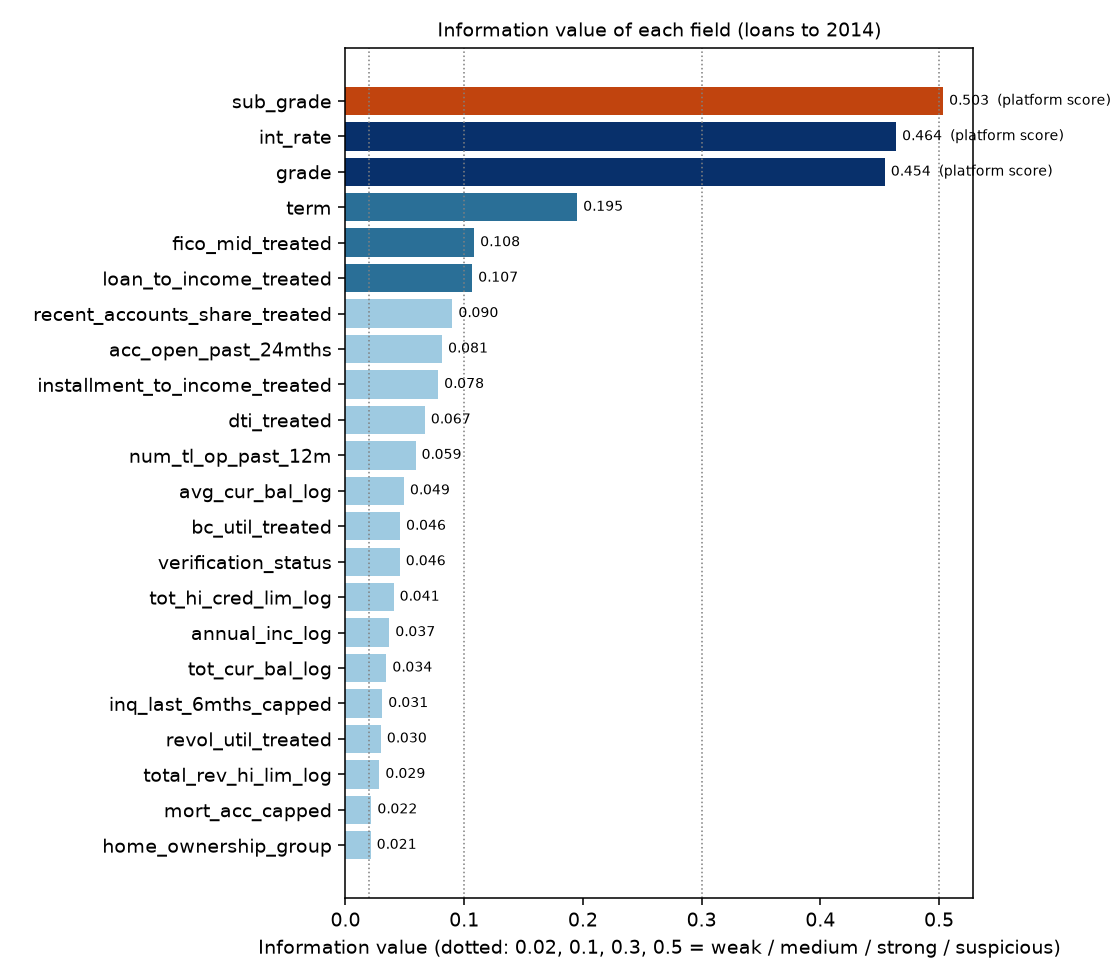

In [13]:
iv = pd.read_csv("reports/a4_iv_ranking/tables/iv_ranking.csv")
print(iv.head(16).to_string(index=False))
print("\nfields by strength:", iv.strength.value_counts().to_dict())
display(Image("reports/a4_iv_ranking/figures/iv_ranking.png", width=700))

**Reading it.**
- **The strongest fields are the platform's own scores:** `sub_grade` 0.50, `int_rate` 0.46, `grade` 0.45. They sit on or just under the "suspicious" line. That is expected: they are the output of the platform's existing risk model, set from the same applicant data, so they echo a model that already knew these fields. They are known at application time and consistent, so they are not leaks, but they are the reason we treat them as a benchmark and test them separately (notebook 03, `DESIGN.md`). Part of `sub_grade`'s edge over `grade` is only that 35 levels give the calculation more room to fit noise.
- **Everything the model builds itself is weaker:** `term` 0.20 (medium), `fico_mid` and `loan_to_income` about 0.11 (medium), the rest weak or useless. That is why the achievable accuracy in this problem is modest.
- The mid-size values are not exact: an IV depends on how a field is binned, so a gap between 0.09 and 0.08 should not be read as a ranking.

**What "too good to be true" looks like.** The same calculation on fields recorded *after* the loan:

In [14]:
print(pd.read_csv("reports/a4_iv_ranking/tables/leak_contrast.csv").round(3).to_string(index=False))

# noise floor: IV of FICO when the default labels are shuffled at random (no real relationship)
rng = np.random.default_rng(0)
xv = ds.fico_mid_treated.to_numpy()
for k in (10, 50):
    bins = pd.qcut(xv, k, labels=False, duplicates="drop")
    floor = np.mean([information_value(woe_table(bins, rng.permutation(ds.defaulted.to_numpy()))) for _ in range(20)])
    print(f"noise floor with {k} bins (labels shuffled, average of 20): IV = {floor:.4f}")

               field  known_at_application    iv   strength
bureau_recovery_flag                 False 9.374 suspicious
          recoveries                 False 5.633 suspicious
last_fico_range_high                 False 3.564 suspicious
     last_pymnt_amnt                 False 3.377 suspicious
     total_rec_prncp                 False 2.240 suspicious
         total_pymnt                 False 0.704 suspicious


noise floor with 10 bins (labels shuffled, average of 20): IV = 0.0042


noise floor with 50 bins (labels shuffled, average of 20): IV = 0.0095


**Reading it.** Every post-issue field is far above 0.5 (0.7 to 9.4). An IV in that range means the field *records the outcome*. None of our application-time fields comes near. As a calibration for the other end: with the labels shuffled so that no real relationship exists, a field still shows IV of about 0.004 to 0.01, so values below roughly 0.02 are hard to tell apart from noise, which is why that is the "useless" line.

## 7. Fitted on the fit window only, and stored
All groups, merged levels, bin edges and WoE values are learned from loans issued up to 31 December 2014, then frozen, so 2015 loans cannot influence the rules used to judge them.

In [15]:
print("what the contract stores for categories:", list(spec["category_groupings"].keys()))
print("fields with WoE bins in the spec:", len(spec["woe"]))
print("example (home_ownership_group):", json.dumps(spec["woe"]["home_ownership_group"])[:330], "...")
print("\ntests that guard the rule:")
for f in ("tests/test_woe.py", "tests/test_categorical.py", "tests/test_binning.py"):
    print(*[f"  {Path(f).name}: {l[4:-1]}" for l in Path(f).read_text().splitlines() if l.startswith("def test") and any(w in l for w in ("2015", "fit", "reused", "unseen", "rare"))], sep="\n")

what the contract stores for categories: ['grouping', 'job_groups', 'emp_length_order']
fields with WoE bins in the spec: 37
example (home_ownership_group): {"method": "category_levels", "edges": [], "bins": [{"label": "MORTGAGE", "loans": 7407, "default_rate": 0.1535, "woe": 0.1388}, {"label": "OWN", "loans": 1406, "default_rate": 0.1707, "woe": 0.0109}, {"label": "RENT", "loans": 5560, "default_rate": 0.198, "woe": -0.1698}], "iv": 0.0213, "strength": "weak", "woe_convention": "ln ...

tests that guard the rule:
  test_woe.py: test_unseen_group_gets_neutral_woe_and_missing_is_its_own_group()
  test_woe.py: test_encoder_adds_woe_columns_and_handles_missing_and_unseen()
  test_woe.py: test_2015_loans_do_not_change_the_fitted_bins_or_woe()
  test_categorical.py: test_rare_levels_merge_and_unseen_levels_fall_into_other()
  test_categorical.py: test_category_grouper_adds_group_columns_and_merges_rare_levels()
  test_categorical.py: test_category_grouper_ignores_2015_loans_and_maps_unseen_

## Summary: what the brief asked, and where it is answered

| Brief item | Answered in |
|---|---|
| Normalise `emp_title` into job groups | section 2 (era change, options compared, keyword rules) |
| Order `emp_length` | section 3 |
| Merge rare levels with a stated minimum size | section 4 (1% of fit-window loans) |
| WoE and IV for categorical and binned numeric fields | sections 1, 2d, 5 |
| Rank by IV, and comment on any IV that looks too good to be true | section 6 (`sub_grade` 0.50, the post-issue contrast, the noise floor) |
| Fit on loans to the cutoff and store in `data_spec.json` | section 7 |